In [ ]:
!gdown "1cXugsmhdR2kJUEr229dSmvpWMpgHzo0D"

Downloading...
From (original): https://drive.google.com/uc?id=1cXugsmhdR2kJUEr229dSmvpWMpgHzo0D
From (redirected): https://drive.google.com/uc?id=1cXugsmhdR2kJUEr229dSmvpWMpgHzo0D&confirm=t&uuid=32da24da-569c-43cf-9027-fea964c6bf16
To: /content/ip02-dataset.zip
100% 3.16G/3.16G [00:44<00:00, 71.8MB/s]


In [ ]:
import os
import shutil
from tqdm import tqdm

# --- 1. CONFIGURATION ---
ZIP_PATH = '/content/ip02-dataset.zip' # Update this!
OUTPUT_DIR = '/content/ip102_organized'
EXTRACT_DIR = '/content/ip102_temp'

# --- 2. FAST EXTRACTION ---
if not os.path.exists(EXTRACT_DIR):
    print("Step 1: Extracting ZIP (Using High-Speed Linux Unzip)...")
    !unzip -q {ZIP_PATH} -d {EXTRACT_DIR}

# --- 3. CREATE FILE INDEX (The Secret to Speed) ---
print("Step 2: Indexing files (this makes moving instant)...")
file_index = {}
for root, dirs, files in os.walk(EXTRACT_DIR):
    for f in files:
        if f.endswith(('.jpg', '.jpeg', '.png')):
            file_index[f] = os.path.join(root, f)

# --- 4. LOAD METADATA ---
def find_meta(name):
    for root, dirs, files in os.walk(EXTRACT_DIR):
        if name in files: return os.path.join(root, name)
    return None

classes_txt = find_meta('classes.txt')
train_txt = find_meta('train.txt')
val_txt = find_meta('val.txt')
test_txt = find_meta('test.txt')

# Build Class Map
classes_map = {}
with open(classes_txt, 'r') as f:
    for line in f:
        p = line.strip().split()
        if p: classes_map[p[0]] = "_".join(p[1:])

# Detect Indexing
with open(train_txt, 'r') as f:
    first_label = f.readline().split()[1]
    is_zero_indexed = (first_label == '0')

# --- 5. ULTRA-FAST ORGANIZATION ---
def fast_organize(split_name, txt_path):
    print(f"Organizing {split_name}...")
    with open(txt_path, 'r') as f:
        lines = f.readlines()

    for line in tqdm(lines):
        parts = line.strip().split()
        if len(parts) < 2: continue
        img_name, label_id = parts[0], parts[1]

        # Handle the 0 vs 1 index automatically
        lookup_id = str(int(label_id) + 1) if is_zero_indexed else label_id

        if lookup_id in classes_map and img_name in file_index:
            class_folder = classes_map[lookup_id]
            dest_dir = os.path.join(OUTPUT_DIR, split_name, class_folder)
            os.makedirs(dest_dir, exist_ok=True)

            # Using os.rename is nearly instantaneous on the same drive
            try:
                os.rename(file_index[img_name], os.path.join(dest_dir, img_name))
            except:
                shutil.copy(file_index[img_name], os.path.join(dest_dir, img_name))

# Run the splits
for s, t in [('train', train_txt), ('val', val_txt), ('test', test_txt)]:
    fast_organize(s, t)

print(f"\nSUCCESS! Data is at {OUTPUT_DIR}")
# Optional: !rm -rf {EXTRACT_DIR}

Step 2: Indexing files (this makes moving instant)...
Organizing train...


100%|██████████| 45095/45095 [00:00<00:00, 1280695.92it/s]


Organizing val...


100%|██████████| 7508/7508 [00:00<00:00, 1027399.90it/s]


Organizing test...


100%|██████████| 22619/22619 [00:00<00:00, 1317633.95it/s]


SUCCESS! Data is at /content/ip102_organized


In [ ]:
!git clone https://github.com/tengshaofeng/ResidualAttentionNetwork-pytorch.git
import sys
# Add the cloned repo to Python's path so we can import from it
sys.path.append('/content/ResidualAttentionNetwork-pytorch')

Cloning into 'ResidualAttentionNetwork-pytorch'...
remote: Enumerating objects: 184, done.
remote: Counting objects: 100% (10/10), done.
remote: Compressing objects: 100% (6/6), done.
remote: Total 184 (delta 4), reused 4 (delta 4), pack-reused 174 (from 1)
Receiving objects: 100% (184/184), 142.60 MiB | 35.67 MiB/s, done.
Resolving deltas: 100% (68/68), done.


In [ ]:
import glob
import os
import sys
import re # Import the re module for regular expressions

# Path to the cloned repository's model files
# Corrected path to target the actual model directory
model_directory = '/content/ResidualAttentionNetwork-pytorch/Residual-Attention-Network/model'
model_files = glob.glob(os.path.join(model_directory, '*.py'))

patched_files = []
if not model_files:
    print(f"No Python files found in {model_directory}. Please check the path.")
else:
    print(f"Found {len(model_files)} model files to patch.")

# Read, patch, and overwrite each file
for filepath in model_files:
    print(f"Patching: {filepath}")
    with open(filepath, 'r') as f:
        code = f.read()

    original_code = code

    # Use a regular expression to find any division operator ('/' or multiple '/////')
    # followed by optional spaces and a digit, and replace it with '//' and the digit.
    # This handles cases like 'X/Y', 'X / Y', 'X /// Y', 'X ///// Y' -> 'X // Y'
    code = re.sub(r'/{1,}(\s*)(\d)', r'//\1\2', code)

    if code != original_code:
        with open(filepath, 'w') as f:
            f.write(code)
        print(f"Successfully patched {filepath}")
        patched_files.append(filepath)
    else:
        print(f"No changes needed for {filepath}")

print("Float division patching process completed!")

# --- Force reload of patched modules ---
# Only reload if files were actually patched, and the modules are already loaded.
if patched_files:
    print("Attempting to reload patched modules...")
    # List modules that might need reloading based on known dependencies
    modules_to_check = ['model.basic_layers', 'model.residual_attention_network', 'model.attention_module']

    for module_name in modules_to_check:
        # Check if the module is currently loaded
        if module_name in sys.modules:
            print(f"Reloading {module_name}...")
            # Delete the module from sys.modules to force a fresh import later
            del sys.modules[module_name]
        else:
            print(f"{module_name} not yet loaded, no explicit reload needed.")
    print("Module reload check completed. Subsequent imports will use the patched versions.")

Found 3 model files to patch.
Patching: /content/ResidualAttentionNetwork-pytorch/Residual-Attention-Network/model/basic_layers.py
No changes needed for /content/ResidualAttentionNetwork-pytorch/Residual-Attention-Network/model/basic_layers.py
Patching: /content/ResidualAttentionNetwork-pytorch/Residual-Attention-Network/model/residual_attention_network.py
No changes needed for /content/ResidualAttentionNetwork-pytorch/Residual-Attention-Network/model/residual_attention_network.py
Patching: /content/ResidualAttentionNetwork-pytorch/Residual-Attention-Network/model/attention_module.py
No changes needed for /content/ResidualAttentionNetwork-pytorch/Residual-Attention-Network/model/attention_module.py
Float division patching process completed!


In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

DATASET_TRAIN_PATH = '/content/ip102_organized/train'
DATASET_VAL_PATH = '/content/ip102_organized/val'
BATCH_SIZE = 128 # Increased for massive speed

# 1. Change Resize to 32x32 and remove RandomCrop
transform_train = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Reload datasets
train_dataset = datasets.ImageFolder(root=DATASET_TRAIN_PATH, transform=transform_train)
val_dataset = datasets.ImageFolder(root=DATASET_VAL_PATH, transform=transform_val)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Loaded {len(train_dataset)} training images at 32x32 resolution.")

Loaded 45095 training images at 32x32 resolution.


In [ ]:
%cd /content/ResidualAttentionNetwork-pytorch/Residual-Attention-Network/
from model.residual_attention_network import ResidualAttentionModel_92_32input_update
import torch
import torch.nn as nn

PRETRAINED_WEIGHTS_PATH = '/content/ResidualAttentionNetwork-pytorch/Residual-Attention-Network/model_92_sgd.pkl'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 1. Build the specific 32x32 skeleton
model = ResidualAttentionModel_92_32input_update()

# 2. Load and filter weights
print("Loading pretrained CIFAR .pkl weights...")
checkpoint = torch.load(PRETRAINED_WEIGHTS_PATH, map_location=device)
state_dict = checkpoint['state_dict'] if 'state_dict' in checkpoint else checkpoint

model_state_dict = model.state_dict()
pretrained_state_dict = {}

for k, v in state_dict.items():
    name = k.replace('module.', '')
    if name in model_state_dict and v.size() == model_state_dict[name].size():
        pretrained_state_dict[name] = v

print(f"Matched and loaded {len(pretrained_state_dict)} out of {len(model_state_dict)} layers!")
model.load_state_dict(pretrained_state_dict, strict=False)

# 3. Modify the final classification layer for IP102 (102 classes)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 102)

# 4. Move to GPU
model = model.to(device)
print("CIFAR RAN Model ready for training!")

/content/ResidualAttentionNetwork-pytorch/Residual-Attention-Network
Using device: cuda
Loading pretrained CIFAR .pkl weights...
Matched and loaded 791 out of 940 layers!
CIFAR RAN Model ready for training!


In [ ]:
# 1. Get a few keys from the PKL file
print("--- PKL FILE LAYER NAMES ---")
pkl_keys = list(state_dict.keys())
for k in pkl_keys[:10]:
    # Print the name and the shape of the weight tensor
    print(f"{k}  --> Shape: {state_dict[k].size()}")

print("\n--- OUR MODEL LAYER NAMES ---")
# 2. Get a few keys from our empty Model
model_keys = list(model_state_dict.keys())
for k in model_keys[:10]:
    print(f"{k}  --> Shape: {model_state_dict[k].size()}")

--- PKL FILE LAYER NAMES ---
conv1.0.weight  --> Shape: torch.Size([32, 3, 3, 3])
conv1.1.weight  --> Shape: torch.Size([32])
conv1.1.bias  --> Shape: torch.Size([32])
conv1.1.running_mean  --> Shape: torch.Size([32])
conv1.1.running_var  --> Shape: torch.Size([32])
residual_block1.bn1.weight  --> Shape: torch.Size([32])
residual_block1.bn1.bias  --> Shape: torch.Size([32])
residual_block1.bn1.running_mean  --> Shape: torch.Size([32])
residual_block1.bn1.running_var  --> Shape: torch.Size([32])
residual_block1.conv1.weight  --> Shape: torch.Size([32, 32, 1, 1])

--- OUR MODEL LAYER NAMES ---
conv1.0.weight  --> Shape: torch.Size([32, 3, 3, 3])
conv1.1.weight  --> Shape: torch.Size([32])
conv1.1.bias  --> Shape: torch.Size([32])
conv1.1.running_mean  --> Shape: torch.Size([32])
conv1.1.running_var  --> Shape: torch.Size([32])
conv1.1.num_batches_tracked  --> Shape: torch.Size([])
residual_block1.bn1.weight  --> Shape: torch.Size([32])
residual_block1.bn1.bias  --> Shape: torch.Size([32]

## Training Loop Setup

Now that the data is loaded and the model is prepared, let's set up the training loop. This involves defining the optimizer, the loss function, and iterating through the dataset for a specified number of epochs.

In [ ]:
import torch.optim as optim
# --- 6. DEFINE HYPERPARAMETERS, LOSS FUNCTION, AND OPTIMIZER ---

NUM_EPOCHS = 10
LEARNING_RATE = 0.0001

# Loss Function
criterion = nn.CrossEntropyLoss()

# Optimizer (SGD is commonly used for Attention Networks)
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.9)

# Learning Rate Scheduler (optional, but often helpful)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

print(f"Training configured for {NUM_EPOCHS} epochs with learning rate {LEARNING_RATE}")

Training configured for 10 epochs with learning rate 0.0001


## Training Function

This function will handle the forward pass, backward pass, and optimization steps for each epoch. We'll track the training loss and accuracy.

In [ ]:
# --- 7. TRAINING LOOP ---
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs, device):
    model.train()  # Set the model to training mode

    # Lists to store metrics for plotting
    train_losses = []
    train_accs = []
    val_losses = []
    val_accs = []

    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        # --- Training Phase ---
        model.train() # Ensure model is in training mode
        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in tqdm(train_loader, desc=f'Training Epoch {epoch+1}'):
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        scheduler.step() # Update learning rate

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = running_corrects.double() / len(train_loader.dataset)
        train_losses.append(epoch_train_loss)
        train_accs.append(epoch_train_acc.item()) # .item() to get scalar from tensor

        print(f'Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f}')

        # --- Validation Phase ---
        model.eval() # Set model to evaluation mode
        val_running_loss = 0.0
        val_running_corrects = 0

        with torch.no_grad(): # Disable gradient calculation for validation
            for inputs, labels in tqdm(val_loader, desc=f'Validation Epoch {epoch+1}'):
                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * inputs.size(0)
                val_running_corrects += torch.sum(preds == labels.data)

        epoch_val_loss = val_running_loss / len(val_loader.dataset)
        epoch_val_acc = val_running_corrects.double() / len(val_loader.dataset)
        val_losses.append(epoch_val_loss)
        val_accs.append(epoch_val_acc.item())

        print(f'Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}')

    print('\nTraining complete!')
    return model, train_losses, train_accs, val_losses, val_accs

# Call the training function
trained_model, train_losses, train_accs, val_losses, val_accs = train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, NUM_EPOCHS, device)


Epoch 1/10
----------


Training Epoch 1: 100%|██████████| 353/353 [03:30<00:00,  1.68it/s]


Train Loss: 4.5568 Acc: 0.0628


Validation Epoch 1: 100%|██████████| 59/59 [00:26<00:00,  2.22it/s]


Val Loss: 4.4933 Acc: 0.0958

Epoch 2/10
----------


Training Epoch 2: 100%|██████████| 353/353 [03:24<00:00,  1.72it/s]


... (9 outputs left out)

Validation Epoch 4: 100%|██████████| 59/59 [00:26<00:00,  2.21it/s]


Val Loss: 4.2637 Acc: 0.1107

Epoch 5/10
----------


Training Epoch 5:  10%|█         | 36/353 [00:21<03:11,  1.65it/s]


KeyboardInterrupt: 

In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models
import torch.nn.functional as F

class TrueRANStyleAttention(nn.Module):
    def __init__(self, in_channels):
        super(TrueRANStyleAttention, self).__init__()
        # 1. Bottom-Up: Zoom out to get global context
        self.downsample = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        # 2. Process features at the lower resolution
        # We shrink the channels by 4 (bottleneck) to save memory, then expand them back
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, in_channels // 4, kernel_size=1, bias=False),
            nn.BatchNorm2d(in_channels // 4),
            nn.ReLU(inplace=True)
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(in_channels // 4, in_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(in_channels)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # Zoom out
        down = self.downsample(x)

        # Build the mask
        mask = self.conv1(down)
        mask = self.conv2(mask)

        # 3. Top-Down: Zoom back in to match original feature size
        mask = F.interpolate(mask, size=x.size()[2:], mode='bilinear', align_corners=False)
        mask = self.sigmoid(mask)

        # 4. The RAN Innovation: (1 + Mask) * Features
        return x * (1 + mask)


class ResNetAttentionHybrid(nn.Module):
    def __init__(self, num_classes=102):
        super(ResNetAttentionHybrid, self).__init__()

        # 1. The Pretrained ResNet-50 Trunk
        print("Loading Pretrained ResNet-50 Trunk...")
        resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        self.trunk = nn.Sequential(*list(resnet.children())[:-2])

        # Freeze the trunk
        for param in self.trunk.parameters():
            param.requires_grad = True

        # 2. The TRUE Residual Attention Module
        # ResNet-50 outputs 2048 channels before the final pooling
        self.attention_module = TrueRANStyleAttention(in_channels=2048)

        # 3. Final pooling and classification
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        # Pass image through frozen ResNet
        features = self.trunk(x)

        # Apply true RAN bottom-up top-down residual attention
        attended_features = self.attention_module(features)

        # Classify
        out = self.pool(attended_features)
        out = torch.flatten(out, 1)
        out = self.fc(out)

        return out

# Initialize the model
model = ResNetAttentionHybrid(num_classes=102)
model = model.to(device)
print("True RAN-Style Hybrid Model Ready!")

Loading Pretrained ResNet-50 Trunk...
True RAN-Style Hybrid Model Ready!


In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

DATASET_TRAIN_PATH = '/content/ip102_organized/train'
DATASET_VAL_PATH = '/content/ip102_organized/val'

# CRITICAL: Decrease batch size so the GPU doesn't run out of memory with the larger images
BATCH_SIZE = 32

# 1. Change Resize to 224x224 (ImageNet standard)
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Reload datasets
train_dataset = datasets.ImageFolder(root=DATASET_TRAIN_PATH, transform=transform_train)
val_dataset = datasets.ImageFolder(root=DATASET_VAL_PATH, transform=transform_val)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Loaded {len(train_dataset)} training images at 224x224 resolution.")

Loaded 45095 training images at 224x224 resolution.


In [ ]:
import torch.optim as optim

NUM_EPOCHS = 10
LEARNING_RATE = 0.0001

# 1. Loss Function
criterion = nn.CrossEntropyLoss()

# 2. Optimizer (CRITICAL: Notice how we only pass parameters that require gradients!)
optimizer = optim.SGD(filter(lambda p: p.requires_grad, model.parameters()),
                      lr=LEARNING_RATE, momentum=0.9, weight_decay=1e-4)

# 3. Scheduler (Drops the learning rate by 10% every 3 epochs to help fine-tune)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

print("Setup complete. Ready to run the training loop!")

Setup complete. Ready to run the training loop!


In [ ]:
# --- 7. TRAINING LOOP ---
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs, device):
    model.train()  # Set the model to training mode

    # Lists to store metrics for plotting
    train_losses = []
    train_accs = []
    val_losses = []
    val_accs = []

    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        # --- Training Phase ---
        model.train() # Ensure model is in training mode
        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in tqdm(train_loader, desc=f'Training Epoch {epoch+1}'):
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        scheduler.step() # Update learning rate

        epoch_train_loss = running_loss / len(train_loader.dataset)
        epoch_train_acc = running_corrects.double() / len(train_loader.dataset)
        train_losses.append(epoch_train_loss)
        train_accs.append(epoch_train_acc.item()) # .item() to get scalar from tensor

        print(f'Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.4f}')

        # --- Validation Phase ---
        model.eval() # Set model to evaluation mode
        val_running_loss = 0.0
        val_running_corrects = 0

        with torch.no_grad(): # Disable gradient calculation for validation
            for inputs, labels in tqdm(val_loader, desc=f'Validation Epoch {epoch+1}'):
                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * inputs.size(0)
                val_running_corrects += torch.sum(preds == labels.data)

        epoch_val_loss = val_running_loss / len(val_loader.dataset)
        epoch_val_acc = val_running_corrects.double() / len(val_loader.dataset)
        val_losses.append(epoch_val_loss)
        val_accs.append(epoch_val_acc.item())

        print(f'Val Loss: {epoch_val_loss:.4f} Acc: {epoch_val_acc:.4f}')

    print('\nTraining complete!')
    return model, train_losses, train_accs, val_losses, val_accs

# Call the training function
trained_model, train_losses, train_accs, val_losses, val_accs = train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, NUM_EPOCHS, device)


Epoch 1/10
----------


Training Epoch 1: 100%|██████████| 1410/1410 [08:45<00:00,  2.68it/s]


Train Loss: 3.3517 Acc: 0.2746


Validation Epoch 1: 100%|██████████| 235/235 [00:46<00:00,  5.09it/s]


Val Loss: 2.7284 Acc: 0.3779

Epoch 2/10
----------


Training Epoch 2: 100%|██████████| 1410/1410 [08:43<00:00,  2.69it/s]


... (8 outputs left out)

Train Loss: 1.9099 Acc: 0.5305


Validation Epoch 4: 100%|██████████| 235/235 [00:46<00:00,  5.02it/s]


Val Loss: 1.9075 Acc: 0.5261

Epoch 5/10
----------


Training Epoch 5:  24%|██▍       | 335/1410 [02:04<06:42,  2.67it/s]

In [ ]:
# Call your original training function
trained_model, train_losses, train_accs, val_losses, val_accs = train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, NUM_EPOCHS, device)

# --- ADD THIS LINE ---
# This takes the brain from RAM and permanently writes it to a file on your Drive
torch.save(trained_model.state_dict(), '/content/drive/MyDrive/ip102_final_model.pth')
print("Final model permanently saved to Drive!")

## Training Performance Visualization

Let's visualize the training and validation loss and accuracy over the epochs to understand the model's learning progress. We'll also generate a confusion matrix to evaluate the classification performance on the validation set.

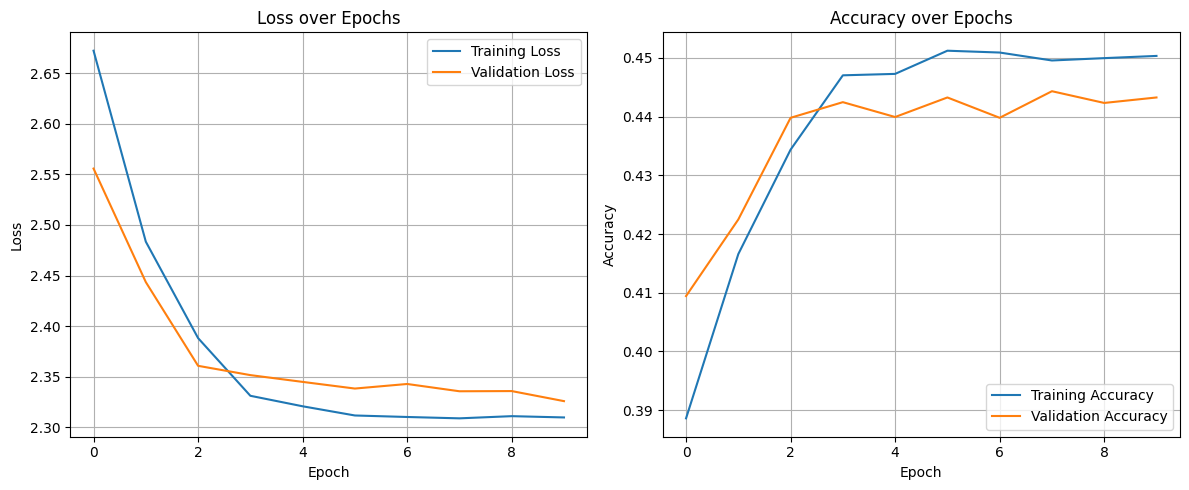

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Plotting Loss Curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plotting Accuracy Curves
plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Training Accuracy')
plt.plot(val_accs, label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Confusion Matrix

Let's generate a confusion matrix to see how well the model classifies each category on the validation set.

Generating Confusion Matrix: 100%|██████████| 235/235 [00:46<00:00,  5.01it/s]


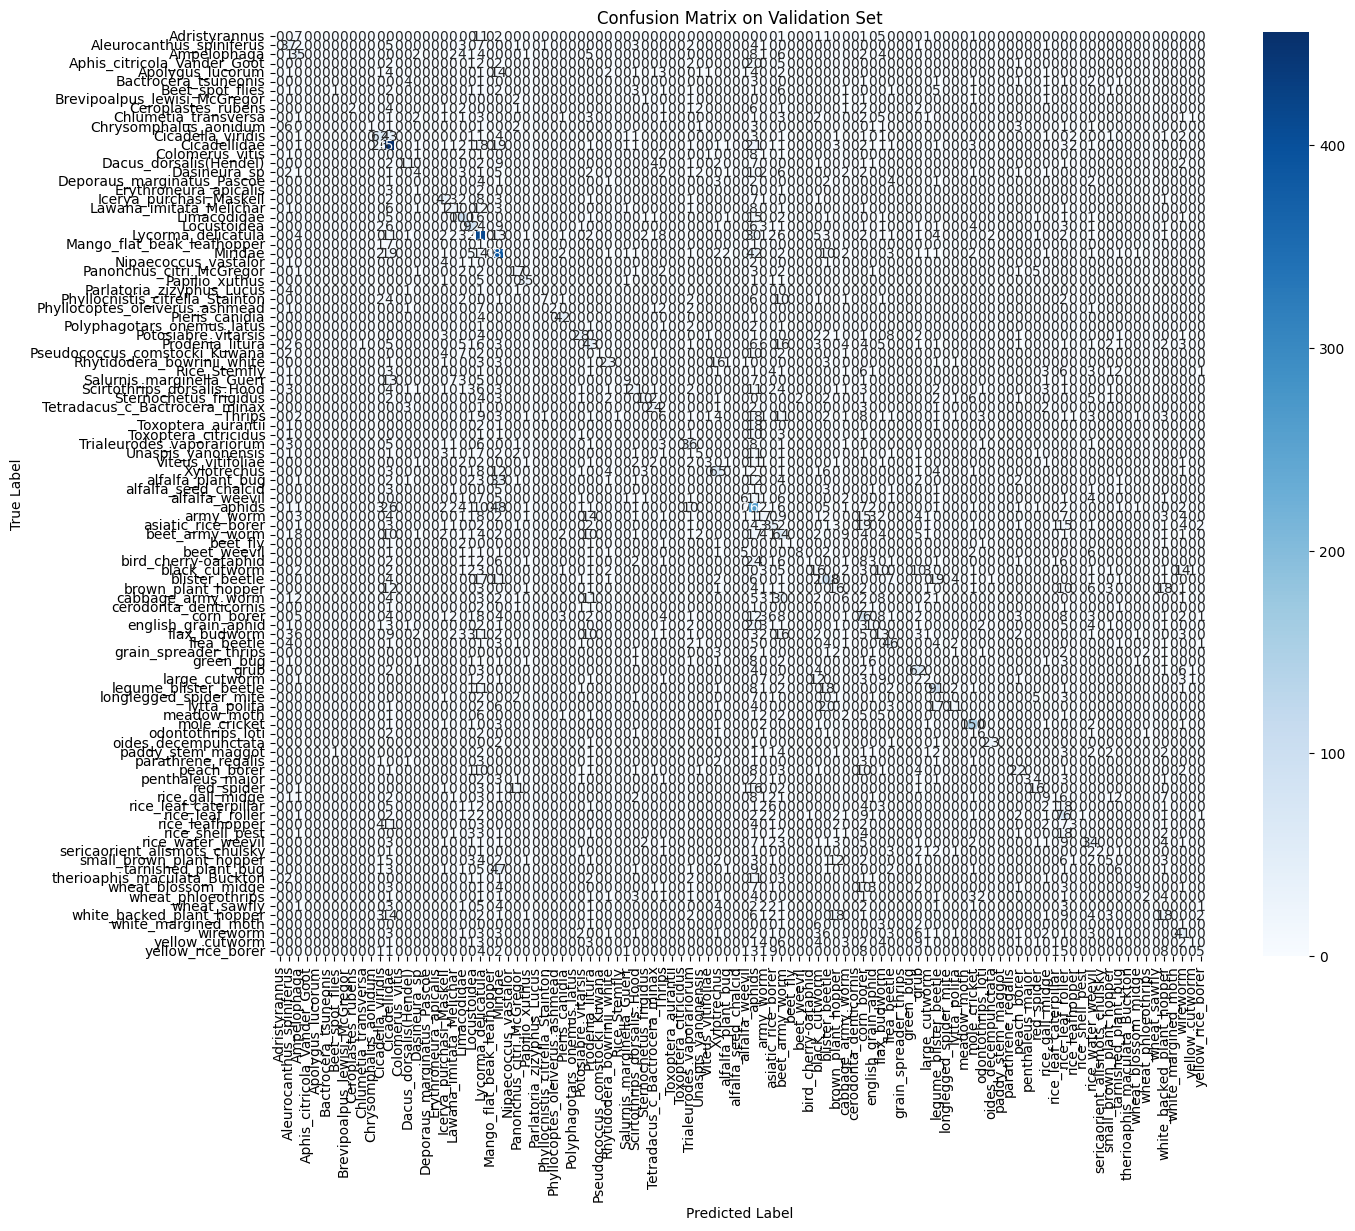

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Get all predictions and true labels for the validation set
all_preds = []
all_labels = []

trained_model.eval()
with torch.no_grad():
    for inputs, labels in tqdm(val_loader, desc='Generating Confusion Matrix'):
        inputs = inputs.to(device)
        outputs = trained_model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Compute the confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot the confusion matrix
plt.figure(figsize=(15, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=val_dataset.classes, yticklabels=val_dataset.classes)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix on Validation Set')
plt.show()